<a href="https://colab.research.google.com/github/nattaponm/Teach_Pysteps_KKN_summerStorm/blob/main/notebooks/02_storm_intensity_hail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2: ความแรงของพายุ ฝน และสัญญาณลูกเห็บ
### Z–R relationships, rainfall accumulation, convective/stratiform separation and hail indicators

⏱️ เวลาเรียนโดยประมาณ **75 นาที** | ต้องผ่าน: Notebook 1

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **แปลง reflectivity เป็นอัตราฝน** ด้วยความสัมพันธ์ Z–R หลายแบบ และอธิบายผลของ **hail cap**
2. **คำนวณฝนสะสม** ณ จุดที่เกิดความเสียหาย และเข้าใจความไม่แน่นอนของการประมาณฝนจากเรดาร์
3. **แยกฝน convective กับ stratiform** และใช้ติดตามการ "รวมตัว" ของพายุ (upscale growth)
4. **ประเมินสัญญาณลูกเห็บ** จากข้อมูลเรดาร์ 2 km และบอกข้อจำกัดของเรดาร์ที่มีเพียง 4 มุมยก
5. **เตรียมข้อมูลเป็น dBR** สำหรับใช้กับ pysteps ใน NB3–NB6

## 📖 1. แนวคิดและสมการ

### 1.1 ความสัมพันธ์ Z–R
เรดาร์วัด $Z$ (ผลรวมของเส้นผ่านศูนย์กลางหยดน้ำยกกำลังหก) ไม่ได้วัดฝนโดยตรง จึงต้องใช้ความสัมพันธ์เชิงประสบการณ์
$$ Z = a\,R^{b} \quad\Longrightarrow\quad R = \left(\frac{10^{\,\mathrm{dBZ}/10}}{a}\right)^{1/b}\quad [\mathrm{mm\,h^{-1}}] $$
| ชุดค่า | $a$ | $b$ | ใช้กับ |
|---|---|---|---|
| Marshall–Palmer | 200 | 1.6 | ฝนทั่วไป (ค่าตั้งต้นของ pysteps) |
| WSR-88D convective | 300 | 1.4 | ฝนพายุฟ้าคะนอง (สหรัฐฯ) |
| Rosenfeld tropical | 250 | 1.2 | ฝนเขตร้อนที่มีหยดน้ำเล็กจำนวนมาก (warm-rain process) |

**Hail cap:** ลูกเห็บสะท้อนคลื่นแรงมาก ถ้าแปลง 60 dBZ เป็นฝนตรง ๆ จะได้ฝน > 200 mm/h ซึ่งเกินจริง จึง **ตัดค่าที่สูงกว่า ~53–55 dBZ** ก่อนแปลง

### 1.2 ฝนสะสมและการแปลงเป็น dBR
$$ P\ [\mathrm{mm}] = \sum_{k} R_k\,\frac{\Delta t}{60},\qquad \mathrm{dBR} = 10\log_{10} R $$
pysteps ทำงานบน **dBR** (ค่าน้อยกว่า threshold 0.1 mm/h กำหนดเป็น zerovalue = −15 dBR) เพราะการกระจายตัวของฝนในหน่วย log ใกล้เคียงการแจกแจงปกติมากกว่า

### 1.3 แยก convective / stratiform (Steiner et al., 1995)
pixel เป็น **convective** ถ้า (1) $Z \ge 40$ dBZ หรือ (2) "โดดเด่น" กว่าพื้นหลัง $Z_{bg}$ (ค่าเฉลี่ยในรัศมี 11 km)
$$ \Delta Z = Z - Z_{bg} \ \ge\ 10 - \frac{Z_{bg}^2}{180}\qquad (0 \le Z_{bg} < 42.43\ \mathrm{dBZ}) $$
พายุที่เพิ่งก่อตัวมีสัดส่วน convective สูง เมื่อเซลล์ต่าง ๆ **รวมตัว (upscale growth)** จะมีฝน stratiform กว้างขึ้น

### 1.4 สัญญาณลูกเห็บจากเรดาร์
- **Z ≥ 50–55 dBZ** ที่ระดับต่ำ และ **แกนพายุที่คงอยู่นาน** (หลาย scan ติดกัน)
- เกณฑ์ที่ดีกว่าต้องใช้ข้อมูล 3 มิติ เช่น **Waldvogel et al. (1979):** ถ้าความสูงของ echo 45 dBZ สูงกว่าระดับเยือกแข็ง $H_0$ อย่างน้อย 1.4 km → มีโอกาสเกิดลูกเห็บ
$$ \Delta H = H_{45\,\mathrm{dBZ}} - H_{0^\circ\mathrm{C}} \ \ge\ 1.4\ \mathrm{km} $$
- **ข้อจำกัดของ KKN ในเคสนี้:** มีแค่ 4 มุมยก และเป็นคลื่น **C-band** ซึ่งถูก **ลดทอน (attenuation)** เมื่อผ่านฝนหนัก/ลูกเห็บ → ค่า Z ด้านหลังแกนพายุต่ำกว่าความจริง

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Pysteps_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 cartopy netCDF4 geopandas metpy cmweather
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "kkn_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.data_io import load_pcappi, time_index
from utils import mapplot as mp
from utils import kkn_tools as kt
from utils import sounding_tools as st
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 686.9/686.9 kB 13.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 106.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 424.4/424.4 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 82.6 MB/s eta 0:00:00
✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Pysteps_KKN_summerStorm/data


In [2]:
Z, meta = load_pcappi(DATA)
ts = meta["timestamps"]
DT = meta["accutime"]                                   # 15 นาที
reports = kt.load_reports(DATA, meta)
date0 = ts[0].replace(hour=0, minute=0)
i_pk = time_index(meta, "09:45")                         # ช่วงเกิดเหตุที่หนองบัวลำภู
NW = kt.box_around(meta, 102.3, 17.25, 110)              # กรอบซูมด้านตะวันตกเฉียงเหนือ (เลย–หนองบัวลำภู–หนองคาย)
snd = st.load_sounding(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
H0 = st.isotherm_height(snd, 0.0) - meta["radar_alt_m"]          # ระดับเยือกแข็งเหนือเรดาร์ (m)
H20 = st.isotherm_height(snd, -20.0) - meta["radar_alt_m"]
print(f"เวลาอ้างอิง: {mp.tlabel(ts[i_pk])} | ระดับ 0 °C ≈ {H0/1000:.2f} km, −20 °C ≈ {H20/1000:.2f} km เหนือเรดาร์")

เวลาอ้างอิง: 09:45 UTC (16:45 LT) | ระดับ 0 °C ≈ 4.95 km, −20 °C ≈ 8.30 km เหนือเรดาร์


## 🌧️ 3. จาก dBZ เป็นอัตราฝน: Z–R สามแบบ

In [3]:
dbz_ref = np.array([20, 30, 40, 45, 50, 55, 60])
tab = pd.DataFrame({name: kt.dbz_to_rainrate(dbz_ref, a, b, hail_cap=None, min_dbz=0)
                    for name, (a, b) in kt.ZR_SETS.items()}, index=dbz_ref)
tab.index.name = "dBZ"
print("อัตราฝน (mm/h) ที่ได้จากแต่ละ Z–R (ยังไม่ตัด hail cap)")
tab.round(1)

อัตราฝน (mm/h) ที่ได้จากแต่ละ Z–R (ยังไม่ตัด hail cap)


,Marshall-Palmer,WSR-88D convective,Rosenfeld tropical
dBZ,,,
20,0.6,0.5,0.5
30,2.7,2.4,3.2
40,11.5,12.2,21.6
45,23.7,27.9,56.5
50,48.6,63.4,147.4
55,99.9,144.3,384.6
60,205.0,328.4,1004.0


บันทึกรูปแล้ว: figures/nb2_zr_comparison.png, figures/nb2_zr_comparison.pdf


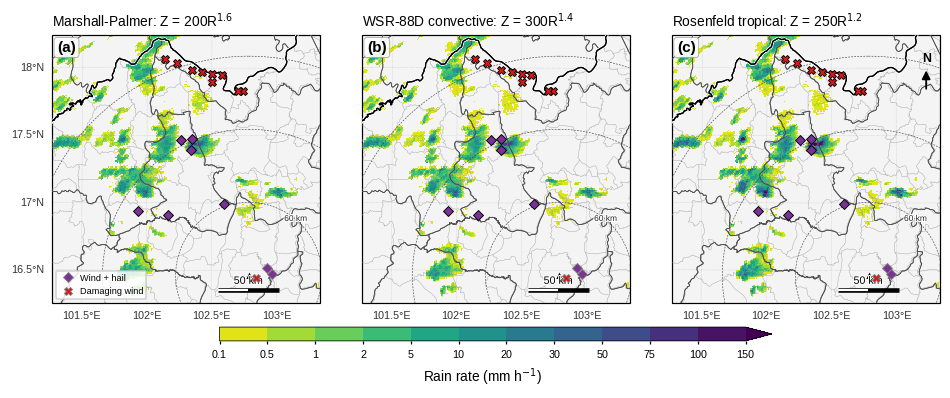

In [4]:
fig, axs = mp.map_panels(1, 3, meta, panel_width=2.9, zoom=NW)
for k, (ax, (name, (a, b))) in enumerate(zip(axs, kt.ZR_SETS.items())):
    R = kt.dbz_to_rainrate(Z[i_pk], a, b, hail_cap=55)
    im = mp.radar_map(ax, R, meta, units="mm/h", zoom=NW, title=f"{name}: Z = {a:g}R$^{{{b:g}}}$",
                      gridline_labels=("left", "bottom") if k == 0 else ("bottom",), north=(k == 2))
    mp.add_reports(ax, reports, legend=(k == 0))
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs)
mp.save_figure(fig, "nb2_zr_comparison")
plt.show()

ที่ 50 dBZ ทั้งสามสูตรให้ฝนต่างกันได้ **มากกว่า 2 เท่า** — การเลือก Z–R เป็นแหล่งความไม่แน่นอนใหญ่ที่สุดของการประมาณฝนจากเรดาร์
งานวิจัยจริงต้อง **สอบเทียบ (calibrate) กับมาตรวัดฝน** ของกรมอุตุนิยมวิทยาหรือกรมชลประทาน

## 💧 4. ฝนสะสม 05:00–17:00 UTC (12:00–24:00 น.)

บันทึกรูปแล้ว: figures/nb2_rain_accumulation.png, figures/nb2_rain_accumulation.pdf


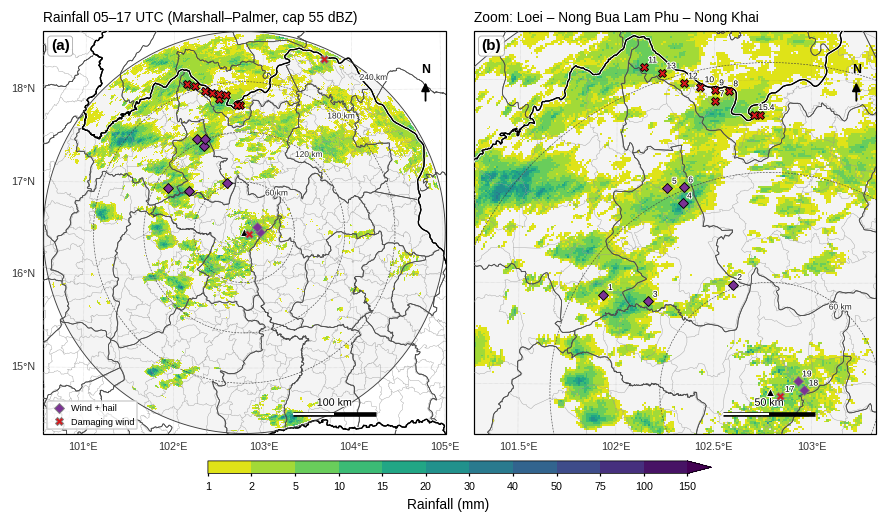

In [5]:
win = slice(time_index(meta, "05:00"), time_index(meta, "17:00") + 1)
R_mp = kt.dbz_to_rainrate(Z[win], *kt.ZR_SETS["Marshall-Palmer"], hail_cap=55)
P_mp = kt.accumulate(R_mp, DT)
P_mp[~meta["coverage"]] = np.nan

fig, axs = mp.map_panels(1, 2, meta, panel_width=4.0)
im = mp.radar_map(axs[0], P_mp, meta, units="mm", ptype="depth", title="Rainfall 05–17 UTC (Marshall–Palmer, cap 55 dBZ)")
mp.add_reports(axs[0], reports)
mp.radar_map(axs[1], P_mp, meta, units="mm", ptype="depth", zoom=NW, title="Zoom: Loei – Nong Bua Lam Phu – Nong Khai",
             gridline_labels=("bottom",))
mp.add_reports(axs[1], reports, legend=False, label_col="id")
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs)
mp.save_figure(fig, "nb2_rain_accumulation")
plt.show()

## 🧩 5. Convective กับ stratiform: พายุ "รวมตัว" เมื่อใด?

บันทึกรูปแล้ว: figures/nb2_conv_strat_maps.png, figures/nb2_conv_strat_maps.pdf


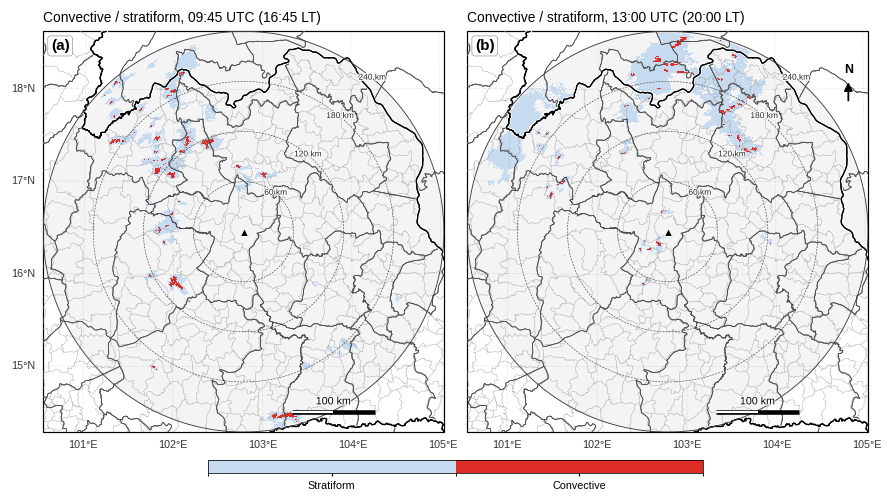

In [6]:
i_up = time_index(meta, "13:00")
fig, axs = mp.map_panels(1, 2, meta, panel_width=4.0)
cmap = plt.matplotlib.colors.ListedColormap(["#c6dbef", "#de2d26"])
for k, (ax, i) in enumerate(zip(axs, [i_pk, i_up])):
    cs = kt.convective_stratiform(Z[i])
    im = mp.field_map(ax, np.where(cs > 0, cs, np.nan), meta, cmap=cmap, levels=[0.5, 1.5, 2.5],
                      title=f"Convective / stratiform, {mp.tlabel(ts[i])}", north=(k == 1),
                      gridline_labels=("left", "bottom") if k == 0 else ("bottom",), extend="neither")
mp.panel_labels(axs)
cb = mp.add_colorbar(fig, im, axs, extend="neither", ticks=[1, 2])
cb.set_ticklabels(["Stratiform", "Convective"])
cb.set_label("")
mp.save_figure(fig, "nb2_conv_strat_maps")
plt.show()

## 🧊 6. สัญญาณลูกเห็บ: แกนพายุที่แรงและคงอยู่นาน
ใน pseudo-CAPPI 2 km ค่า ≥ 50 dBZ พบน้อยมาก (เพียงไม่กี่ pixel) จึงดูแผนที่ **ระยะเวลาที่ Z ≥ 45 dBZ** ก่อน แล้วค่อยดู ≥ 50 dBZ ในแบบฝึกหัด 2.3

จำนวน pixel ที่มี Z ≥ 45 dBZ อย่างน้อย 1 ครั้ง: 2204, ≥ 30 นาที: 128
บันทึกรูปแล้ว: figures/nb2_core_persistence.png, figures/nb2_core_persistence.pdf


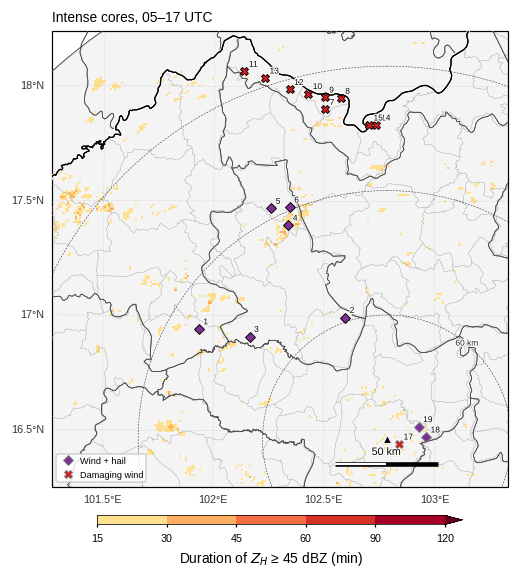

In [7]:
CORE_DBZ = 45
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    persist = np.nansum(Z[win] >= CORE_DBZ, axis=0) * DT          # จำนวนนาทีที่ ≥ 45 dBZ
persist = np.where(meta["coverage"], persist, np.nan)
print(f"จำนวน pixel ที่มี Z ≥ {CORE_DBZ} dBZ อย่างน้อย 1 ครั้ง: {int(np.nansum(persist > 0))}, "
      f"≥ 30 นาที: {int(np.nansum(persist >= 30))}")

core_cmap = plt.matplotlib.colors.ListedColormap(["#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026", "#67001f"])
fig, axs = mp.map_panels(1, 1, meta, panel_width=4.6, zoom=NW)
im = mp.field_map(axs[0], np.where(persist > 0, persist, np.nan), meta, cmap=core_cmap,
                  levels=[15, 30, 45, 60, 90, 120], zoom=NW, extend="max",
                  label=f"Duration of $Z_H$ ≥ {CORE_DBZ} dBZ (min)", title="Intense cores, 05–17 UTC")
mp.add_reports(axs[0], reports, label_col="id")
mp.add_colorbar(fig, im, axs, shrink=0.8)
mp.save_figure(fig, "nb2_core_persistence")
plt.show()

### เรดาร์มองเห็นระดับเยือกแข็งได้หรือไม่? (เรขาคณิตลำคลื่น 4 มุมยก)

บันทึกรูปแล้ว: figures/nb2_beam_vs_isotherms.png, figures/nb2_beam_vs_isotherms.pdf


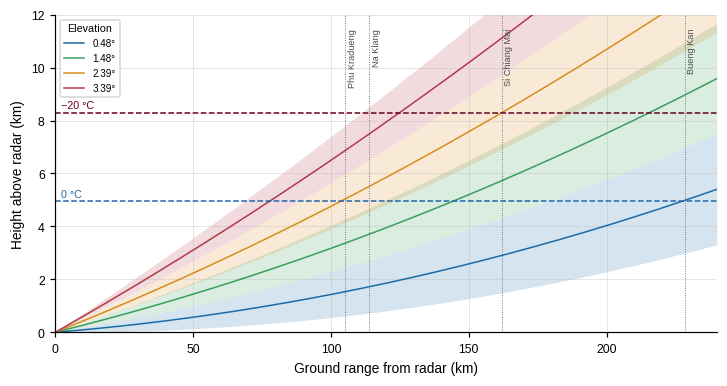

ความสูงลำคลื่นที่อำเภอนากลาง (km เหนือเรดาร์):


,elev_deg,centre_km,bottom_km,top_km,beam_width_km
0,0.48,1.71,0.72,2.71,1.98
1,1.48,3.70,2.71,4.69,1.98
2,2.39,5.50,4.51,6.49,1.98
3,3.39,7.48,6.49,8.47,1.98


In [8]:
rng = np.arange(0, 241, 1.0)
fig, ax = plt.subplots(figsize=(6.5, 3.4), layout="constrained")
colors = ["#1b6ca8", "#3a9e5c", "#d98c1f", "#b23a48"]
for e, c in zip(kt.ELEVATIONS_DEG, colors):
    ax.fill_between(rng, kt.beam_height_km(rng, e - 0.5), kt.beam_height_km(rng, e + 0.5), color=c, alpha=0.18, lw=0)
    ax.plot(rng, kt.beam_height_km(rng, e), color=c, lw=1, label=f"{e:.2f}°")
ax.axhline(H0 / 1000, color="#2166ac", ls="--", lw=1)
ax.axhline(H20 / 1000, color="#67001f", ls="--", lw=1)
ax.text(2, H0 / 1000 + 0.15, "0 °C", color="#2166ac", fontsize=7)
ax.text(2, H20 / 1000 + 0.15, "−20 °C", color="#67001f", fontsize=7)
for name in ["Phu Kradueng", "Na Klang", "Si Chiang Mai", "Bueng Kan"]:
    r = kt.site(reports, name)
    ax.axvline(r["range_km"], color="0.4", lw=0.6, ls=":")
    ax.text(r["range_km"] + 1, 11.5, name, rotation=90, fontsize=6, va="top", color="0.3")
ax.set_xlim(0, 240)
ax.set_ylim(0, 12)
ax.legend(title="Elevation", fontsize=6.5, title_fontsize=7, loc="upper left")
mp.skill_axes(ax, xlabel="Ground range from radar (km)", ylabel="Height above radar (km)")
mp.save_figure(fig, "nb2_beam_vs_isotherms")
plt.show()
print("ความสูงลำคลื่นที่อำเภอนากลาง (km เหนือเรดาร์):")
kt.beam_table(kt.site(reports, "Na Klang")["range_km"]).round(2)

ที่ **นากลาง (~114 km)** ลำคลื่นมุม 3.39° อยู่สูง ~7 km ซึ่ง **สูงกว่าระดับ 0 °C** → ถ้ามีค่า ≥ 45 dBZ ที่มุมนี้ จะเป็นหลักฐานสนับสนุนลูกเห็บตามเกณฑ์ Waldvogel
ข้อมูล pseudo-CAPPI 2 km ใน repo นี้ไม่มีข้อมูลมุมนั้น แต่ไฟล์ polar ใน `data/polar/` (ส่วนเสริมของ NB3) และ repo ที่สองมีให้ศึกษาต่อ

## 🔢 7. เตรียมข้อมูลสำหรับ pysteps: dBZ → R → dBR

Pysteps configuration file found at: /usr/local/lib/python3.13/dist-packages/pysteps/pystepsrc

บันทึกรูปแล้ว: figures/nb2_histograms.png, figures/nb2_histograms.pdf


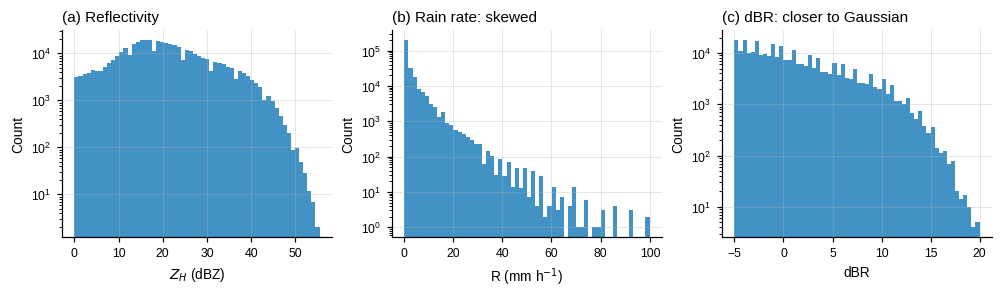

metadata หลังแปลงเป็น dBR: {'unit': 'mm/h', 'transform': 'dB', 'threshold': np.float64(-10.0), 'zerovalue': -15.0}


In [9]:
from pysteps.utils import transformation
R_win = kt.dbz_to_rainrate(Z[win], 200, 1.6, hail_cap=55)
meta_r = dict(meta, unit="mm/h", transform=None, threshold=0.1, zerovalue=0.0)
dBR, meta_dbr = transformation.dB_transform(R_win, meta_r, threshold=0.1, zerovalue=-15.0)
fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), layout="constrained")
for ax, data, lab in zip(axs, [Z[win], R_win, dBR], ["$Z_H$ (dBZ)", "R (mm h$^{-1}$)", "dBR"]):
    v = data[np.isfinite(data)]
    v = v[v > (0.1 if "R (" in lab else -14.9)]
    ax.hist(v, bins=60, color="#4292c6", log=True)
    mp.skill_axes(ax, xlabel=lab, ylabel="Count")
axs[0].set_title("(a) Reflectivity", loc="left")
axs[1].set_title("(b) Rain rate: skewed", loc="left")
axs[2].set_title("(c) dBR: closer to Gaussian", loc="left")
mp.save_figure(fig, "nb2_histograms")
plt.show()
print("metadata หลังแปลงเป็น dBR:", {k: meta_dbr[k] for k in ("unit", "transform", "threshold", "zerovalue")})

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 2.1: Z–R หรือ hail cap — อะไรมีผลต่อฝนสะสมมากกว่า?
คำนวณ **ฝนสะสม 05:00–17:00 UTC** ที่จุด `Na Klang` และ `Phu Kradueng` (ค่าเฉลี่ยในรัศมี 5 km) สำหรับ Z–R ทั้ง 3 แบบ แต่ละแบบทั้ง **มี hail cap 55 dBZ** และ **ไม่มี** (`hail_cap=None`) — รวม 6 กรณี

**คำถาม:** ความแตกต่างระหว่าง Z–R มากกว่าหรือน้อยกว่าผลของ hail cap? ในเคสนี้ hail cap มีผลน้อยเพราะอะไร?

<details>
<summary><b>💡 คำใบ้</b></summary>

- วน `for name, (a, b) in kt.ZR_SETS.items():` และ `for cap in [55, None]:`
- `R = kt.dbz_to_rainrate(Z[win], a, b, hail_cap=cap)` แล้ว `P = kt.accumulate(R, DT)`
- `kt.point_series(P[None], meta, lon, lat, 5, stat="mean")[0]`

</details>

In [10]:
# ✍️ แบบฝึกหัด 2.1 — เขียนโค้ดของคุณที่นี่
# rows = []
# for name, (a, b) in kt.ZR_SETS.items():
#     for cap in [55, None]:
#         ...

In [11]:
#@title ✅ เฉลยแบบฝึกหัด 2.1 (ลองทำเองก่อน! ดับเบิลคลิกเพื่อดูโค้ด แล้วกด ▶ เพื่อรัน)
rows = []
for name, (a, b) in kt.ZR_SETS.items():
    for cap in [55, None]:
        P = kt.accumulate(kt.dbz_to_rainrate(Z[win], a, b, hail_cap=cap), DT)
        row = {"Z-R": name, "hail_cap": cap if cap else "none"}
        for s in ["Na Klang", "Phu Kradueng"]:
            r = kt.site(reports, s)
            row[f"{s} (mm)"] = kt.point_series(P[None], meta, r["lon"], r["lat"], 5, stat="mean")[0]
        rows.append(row)
res21 = pd.DataFrame(rows).round(1)
print(res21.to_string(index=False))
print(f"\nจำนวน pixel-เวลาที่ ≥ 55 dBZ ในช่วงนี้: {int(np.nansum(Z[win] >= 55))} จาก {int(np.isfinite(Z[win]).sum())}")
print("→ Z–R ต่างกันได้ ~2 เท่า แต่ hail cap แทบไม่มีผล เพราะ pseudo-CAPPI 2 km แทบไม่มีค่า ≥ 55 dBZ (C-band attenuation + ลำคลื่นกว้างที่ระยะไกล)")

               Z-R hail_cap  Na Klang (mm)  Phu Kradueng (mm)
   Marshall-Palmer       55           11.8                2.5
   Marshall-Palmer     none           11.8                2.5
WSR-88D convective       55           12.9                2.3
WSR-88D convective     none           12.9                2.3
Rosenfeld tropical       55           24.7                3.4
Rosenfeld tropical     none           24.7                3.4

จำนวน pixel-เวลาที่ ≥ 55 dBZ ในช่วงนี้: 2 จาก 8864884
→ Z–R ต่างกันได้ ~2 เท่า แต่ hail cap แทบไม่มีผล เพราะ pseudo-CAPPI 2 km แทบไม่มีค่า ≥ 55 dBZ (C-band attenuation + ลำคลื่นกว้างที่ระยะไกล)


### 🧪 แบบฝึกหัด 2.2: พายุเริ่ม "รวมตัว" เมื่อใด?
คำนวณ **พื้นที่ convective และ stratiform (km²)** ทุกเวลาตั้งแต่ 05:00 ถึง 17:00 UTC ภายในรัศมี 200 km ด้วย `kt.convective_stratiform` แล้วพล็อตอนุกรมเวลาพร้อม **สัดส่วน convective (%)**

**คำถาม:** สัดส่วน convective สูงสุดช่วงใด และลดลงเมื่อใด? สอดคล้องกับช่วง "upscale growth" ใน NB1 หรือไม่?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `m200 = kt.range_mask(meta, 200)`
- ในแต่ละเวลา `cs = kt.convective_stratiform(Z[i])` แล้ว `np.sum((cs == 2) & m200)`, `np.sum((cs == 1) & m200)`
- ข้ามเวลาที่ `meta["available"][i]` เป็น False

</details>

In [12]:
# ✍️ แบบฝึกหัด 2.2 — เขียนโค้ดของคุณที่นี่
# m200 = kt.range_mask(meta, 200)
# rows = []
# for i in range(time_index(meta, "05:00"), time_index(meta, "17:00") + 1):
#     ...

บันทึกรูปแล้ว: figures/nb2_ex22_conv_strat_timeseries.png, figures/nb2_ex22_conv_strat_timeseries.pdf


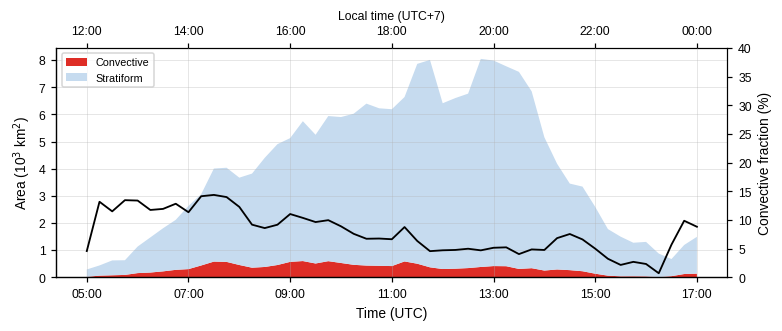

สัดส่วน convective สูงสุด 14% เวลา 07:30 UTC (14:30 LT)
พื้นที่ stratiform สูงสุด 7669 km² เวลา 12:45 UTC (19:45 LT)


In [13]:
#@title ✅ เฉลยแบบฝึกหัด 2.2
m200 = kt.range_mask(meta, 200)
rows = []
for i in range(time_index(meta, "05:00"), time_index(meta, "17:00") + 1):
    if not meta["available"][i]:
        continue
    cs = kt.convective_stratiform(Z[i])
    c, s = np.sum((cs == 2) & m200), np.sum((cs == 1) & m200)
    rows.append({"time": ts[i], "convective_km2": c, "stratiform_km2": s,
                 "conv_frac_pct": 100 * c / max(c + s, 1)})
cf = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 2.9), layout="constrained")
ax.stackplot(cf["time"], cf["convective_km2"] / 1e3, cf["stratiform_km2"] / 1e3,
             colors=["#de2d26", "#c6dbef"], labels=["Convective", "Stratiform"])
ax2 = ax.twinx()
ax2.plot(cf["time"], cf["conv_frac_pct"], "k-", lw=1.2, label="Convective fraction")
ax2.set_ylabel("Convective fraction (%)")
ax2.spines["right"].set_visible(True)
ax2.set_ylim(0, 40)
mp.time_axis(ax, interval_h=2)
mp.skill_axes(ax, xlabel="Time (UTC)", ylabel="Area (10$^3$ km$^2$)")
ax.legend(loc="upper left", fontsize=7)
mp.save_figure(fig, "nb2_ex22_conv_strat_timeseries")
plt.show()
top = cf.loc[cf["conv_frac_pct"].idxmax()]
print(f"สัดส่วน convective สูงสุด {top['conv_frac_pct']:.0f}% เวลา {mp.tlabel(top['time'])}")
print(f"พื้นที่ stratiform สูงสุด {cf['stratiform_km2'].max():.0f} km² เวลา {mp.tlabel(cf.loc[cf['stratiform_km2'].idxmax(), 'time'])}")

### 🧪 แบบฝึกหัด 2.3: จุดที่มีรายงานลูกเห็บ มีแกนพายุแรงนานกว่าหรือไม่?
สำหรับทุกจุดใน `reports` ให้นับ **จำนวนนาทีที่ค่าสูงสุดในรัศมี 5 km ≥ 50 dBZ** และ **≥ 45 dBZ** ในช่วง 05:00–17:00 UTC
จากนั้นเปรียบเทียบค่าเฉลี่ยระหว่างกลุ่มที่ข่าวระบุ "ลูกเห็บ" กับกลุ่ม "ลมแรง" อย่างเดียว

**คำถาม:** ผลสอดคล้องกับรายงานหรือไม่? ระยะจากเรดาร์มีผลต่อการเปรียบเทียบนี้อย่างไร? (ระวัง: ข่าวที่ไม่กล่าวถึงลูกเห็บ ไม่ได้แปลว่าไม่มีลูกเห็บ)

<details>
<summary><b>💡 คำใบ้</b></summary>

- `s = kt.point_series(Z[win], meta, r["lon"], r["lat"], 5)` แล้ว `np.sum(s >= 50) * DT`
- กลุ่ม: `reports["hazard"].str.contains("ลูกเห็บ")`
- `df.groupby("hail_reported")[["min_ge45", "min_ge50", "range_km"]].mean()`

</details>

In [14]:
# ✍️ แบบฝึกหัด 2.3 — เขียนโค้ดของคุณที่นี่

In [15]:
#@title ✅ เฉลยแบบฝึกหัด 2.3
rows = []
for _, r in reports.iterrows():
    s = kt.point_series(Z[win], meta, r["lon"], r["lat"], 5)
    rows.append({"id": r["id"], "district": r["district"], "subdistrict": r["subdistrict"],
                 "hail_reported": "ลูกเห็บ" in r["hazard"], "range_km": r["range_km"],
                 "min_ge45": np.nansum(s >= 45) * DT, "min_ge50": np.nansum(s >= 50) * DT,
                 "max_dbz": np.nanmax(s)})
hail = pd.DataFrame(rows).round(1)
print(hail.to_string(index=False))
print("\nค่าเฉลี่ยตามกลุ่ม:")
print(hail.groupby("hail_reported")[["min_ge45", "min_ge50", "max_dbz", "range_km"]].mean().round(1))
g = hail.groupby("hail_reported")[["min_ge45", "min_ge50"]].mean()
ge50 = hail.loc[hail["min_ge50"] > 0, "subdistrict"].tolist()
print(f"\n→ เฉลี่ยกลุ่มที่รายงานลูกเห็บ: ≥45 dBZ {g.loc[True, 'min_ge45']:.0f} นาที, ≥50 dBZ {g.loc[True, 'min_ge50']:.0f} นาที"
      f" | กลุ่มลมแรง: {g.loc[False, 'min_ge45']:.0f} / {g.loc[False, 'min_ge50']:.0f} นาที")
print(f"  จุดที่มีแกน ≥ 50 dBZ: {ge50} — ทั้งหมดเป็นจุดที่ข่าวระบุลูกเห็บ")
print("  แต่หลายจุดที่รายงานลูกเห็บ (เช่น ภูกระดึง) ไม่ถึง 45 dBZ ที่ 2 km: เซลล์เล็กกว่า pixel/ลำคลื่น, ตำแหน่งตำบลไม่ตรงจุดเกิดเหตุ, attenuation"
      "\n  และจุดที่หนองคาย/บึงกาฬอยู่ไกลกว่า 150 km เรดาร์วัดค่าได้ต่ำลง — ผลจึงปนกับระยะทาง")

 id         district    subdistrict  hail_reported  range_km  min_ge45  min_ge50  max_dbz
  1     Phu Kradueng       Huai Som           True     105.2       0.0       0.0     43.2
  2         Non Sang        Pang Ku           True      62.1       0.0       0.0     40.4
  3    Si Bun Rueang         Na Kok           True      82.8       0.0       0.0     44.3
  4         Na Klang       Kao Kloi           True     113.7      60.0      30.0     51.7
  5     Suwannakhuha          Na Di           True     124.6       0.0       0.0     41.0
  6     Suwannakhuha         Na Dan           True     121.5      30.0      15.0     51.7
  7    Si Chiang Mai   Nong Pla Pak          False     161.9       0.0       0.0     42.5
  8    Si Chiang Mai     Phan Phrao          False     166.0       0.0       0.0     38.0
  9    Si Chiang Mai         Ban Mo          False     167.8       0.0       0.0     33.0
 10    Si Chiang Mai Phraphutthabat          False     171.0       0.0       0.0     41.5
 11       

---
## 📝 สรุป
- **Z–R เป็นแหล่งความไม่แน่นอนใหญ่:** สูตรต่างกันให้ฝนสะสมต่างกันได้ ~2 เท่า ต้องสอบเทียบกับมาตรวัดฝนก่อนใช้งานจริง
- **hail cap แทบไม่มีผล** ในเคสนี้ เพราะ pseudo-CAPPI 2 km ของ C-band มีค่า ≥ 55 dBZ น้อยมาก — ไม่ได้แปลว่าไม่มีลูกเห็บ
- การแยก **convective/stratiform** แสดงให้เห็นการเปลี่ยนจากเซลล์เดี่ยวตอนบ่ายไปเป็นระบบใหญ่ที่มีฝน stratiform กว้างตอนค่ำ
- **แกนพายุ ≥ 50 dBZ ที่คงอยู่ 15–30 นาที** ตรงกับพื้นที่ที่รายงานลูกเห็บในหนองบัวลำภู
- ข้อมูลถูกแปลงเป็น **dBR** พร้อมใช้กับ pysteps ใน NB3–NB6

### ❓ คำถามชวนคิด
1. ถ้าต้องเลือก Z–R เพียงสูตรเดียวสำหรับพายุฤดูร้อนในอีสาน จะเลือกอะไร และจะพิสูจน์ได้อย่างไร?
2. ทำไมเรดาร์ C-band จึงมีปัญหา attenuation มากกว่า S-band? ส่งผลต่อการประเมินลูกเห็บที่หนองคายอย่างไร?
3. ลมกระโชกแรงที่ทำให้บ้านพังเกิดจาก downburst — reflectivity อย่างเดียวบอกได้หรือไม่? ข้อมูลอะไรช่วยได้ (คำใบ้: Doppler, NB3)

**🚀 ต่อยอด (ป.โท):** ใช้ไฟล์ polar ใน `data/polar/` หาค่า Z ที่มุมยก 3.39° เหนือหนองบัวลำภู แล้วประเมิน $\Delta H$ ตามเกณฑ์ Waldvogel

### 📚 เอกสารอ้างอิง
- Marshall, J. S., & Palmer, W. M. (1948). The distribution of raindrops with size. *J. Meteor.*, 5, 165–166.
- Rosenfeld, D., Wolff, D. B., & Atlas, D. (1993). General probability-matched relations between radar reflectivity and rain rate. *J. Appl. Meteor.*, 32, 50–72.
- Steiner, M., Houze, R. A., & Yuter, S. E. (1995). Climatological characterization of three-dimensional storm structure from operational radar and rain gauge data. *J. Appl. Meteor.*, 34, 1978–2007.
- Waldvogel, A., Federer, B., & Grimm, P. (1979). Criteria for the detection of hail cells. *J. Appl. Meteor.*, 18, 1521–1525.
- Pulkkinen, S., et al. (2019). Pysteps v1.0. *Geosci. Model Dev.*, 12, 4185–4219.